In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.tree import DecisionTreeClassifier
from sklearn.tree import plot_tree
from sklearn.metrics import accuracy_score,recall_score,precision_score,f1_score

import warnings
warnings.filterwarnings('ignore')

In [2]:
data = pd.read_csv(r'C:\Users\WINDOWS 11\Desktop\Jupyter Notebook\other stuff\Dataset\csv\churn_data.csv')
data.head()

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [3]:
data.info()

<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   str    
 1   gender            7043 non-null   str    
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   str    
 4   Dependents        7043 non-null   str    
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   str    
 7   MultipleLines     7043 non-null   str    
 8   InternetService   7043 non-null   str    
 9   OnlineSecurity    7043 non-null   str    
 10  OnlineBackup      7043 non-null   str    
 11  DeviceProtection  7043 non-null   str    
 12  TechSupport       7043 non-null   str    
 13  StreamingTV       7043 non-null   str    
 14  StreamingMovies   7043 non-null   str    
 15  Contract          7043 non-null   str    
 16  PaperlessBilling  7043 non-null   str    
 17  Paymen

In [4]:
data['TotalCharges'] = pd.to_numeric(data['TotalCharges'],errors = 'coerce')

In [5]:
data['TotalCharges'].info()

<class 'pandas.Series'>
RangeIndex: 7043 entries, 0 to 7042
Series name: TotalCharges
Non-Null Count  Dtype  
--------------  -----  
7032 non-null   float64
dtypes: float64(1)
memory usage: 55.2 KB


In [6]:
#LabelEncoding
from sklearn.preprocessing import LabelEncoder
#enc = data[['SeniorCitizen','Partner','Dependents','PhoneService','Gender','Churn','InternetService','OnlineSecurity','PaymentMethod','PaperlessBilling']]
lb = LabelEncoder()
new_data = data.drop('customerID',axis = 1)

for col in new_data.columns:
    data[col] = lb.fit_transform(data[col])

In [7]:
data.head()

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,0,0,1,0,1,0,1,0,0,...,0,0,0,0,0,1,2,142,74,0
1,5575-GNVDE,1,0,0,0,34,1,0,0,2,...,2,0,0,0,1,0,3,498,3624,0
2,3668-QPYBK,1,0,0,0,2,1,0,0,2,...,0,0,0,0,0,1,3,436,536,1
3,7795-CFOCW,1,0,0,0,45,0,1,0,2,...,2,2,0,0,1,0,0,266,3570,0
4,9237-HQITU,0,0,0,0,2,1,0,1,0,...,0,0,0,0,0,1,2,729,674,1


In [8]:
data.Contract.value_counts()

Contract
0    3875
2    1695
1    1473
Name: count, dtype: int64

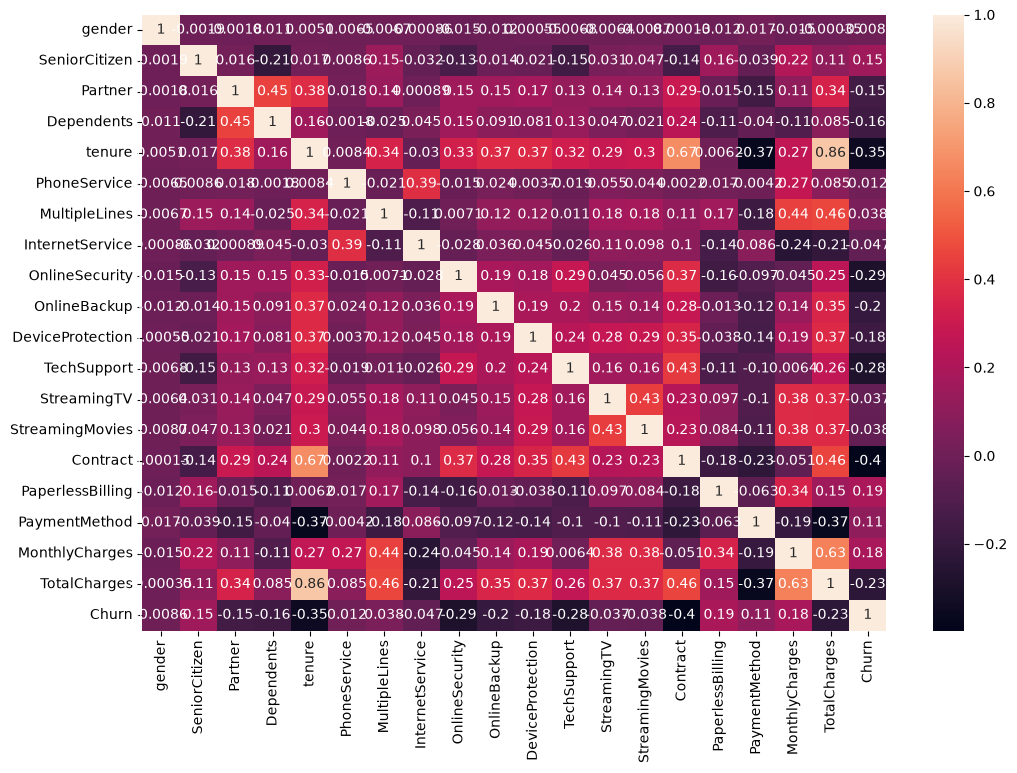

In [9]:
#use heatmap to find correlation of different features on data
plt.figure(figsize = (12,8))
X = data.drop(columns = ['customerID'])
sns.heatmap(X.corr(),annot = True)
plt.show()

In [10]:
from sklearn.preprocessing import StandardScaler
scaler = StandardScaler()
data['MonthlyCharges'] = scaler.fit_transform(data[['MonthlyCharges']])

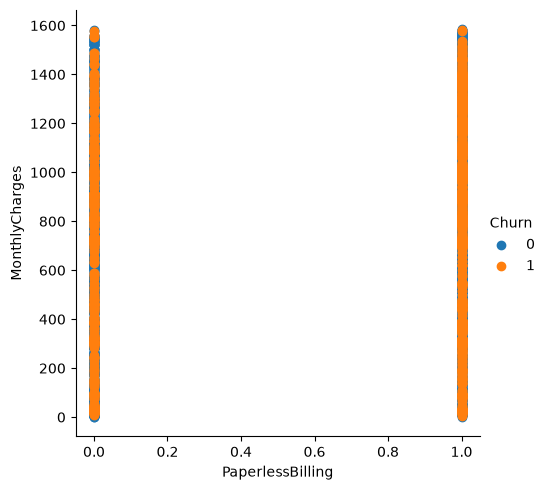

In [11]:
sns.FacetGrid(X,hue = 'Churn',height = 5).map(plt.scatter,'PaperlessBilling','MonthlyCharges').add_legend()

In [12]:
from sklearn.model_selection import train_test_split
X_new = X.drop('Churn',axis= 1)
y = X['Churn']
X_train,X_test,y_train,y_test = train_test_split(X_new,y,test_size = 0.2,random_state = 42)
X_train.head()

,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges
2142,0,0,0,1,21,1,0,0,2,0,2,0,0,2,1,0,3,625,2972
1623,0,0,0,0,54,1,2,1,0,2,0,0,2,2,2,1,0,1230,5458
6074,1,0,1,0,1,0,1,0,0,0,0,0,0,0,0,1,2,62,45
1362,1,0,0,0,4,1,0,1,0,0,0,0,0,0,0,1,2,719,966
6754,1,0,0,1,0,1,2,0,2,2,0,2,0,0,2,1,0,579,6530


In [13]:
model = DecisionTreeClassifier(criterion = 'entropy',random_state = 42)
model.fit(X_train,y_train)
pred = model.predict(X_test)
accuracy = accuracy_score(y_test,pred)
print(f"The model accuracy on testing dataset is :{accuracy} ")

The model accuracy on testing dataset is :0.7239176721078779 


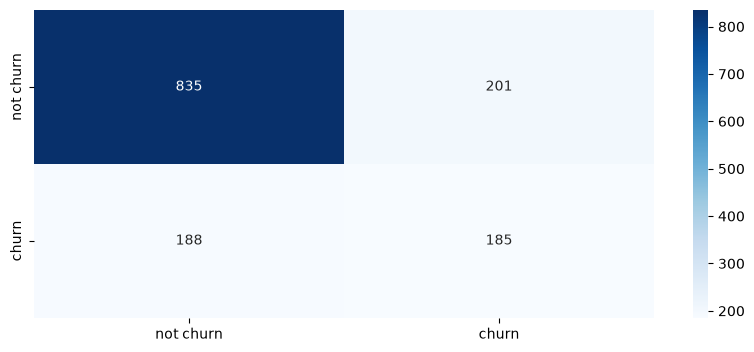

In [14]:
#confusion matrix
from sklearn.metrics import confusion_matrix
cm = confusion_matrix(y_test,pred)

#plotting confusion matrix
plt.figure(figsize = (10,4))
sns.heatmap(cm,annot = True,fmt = 'd',cmap = 'Blues',xticklabels = ['not churn','churn'],yticklabels = ['not churn','churn'])
plt.show()

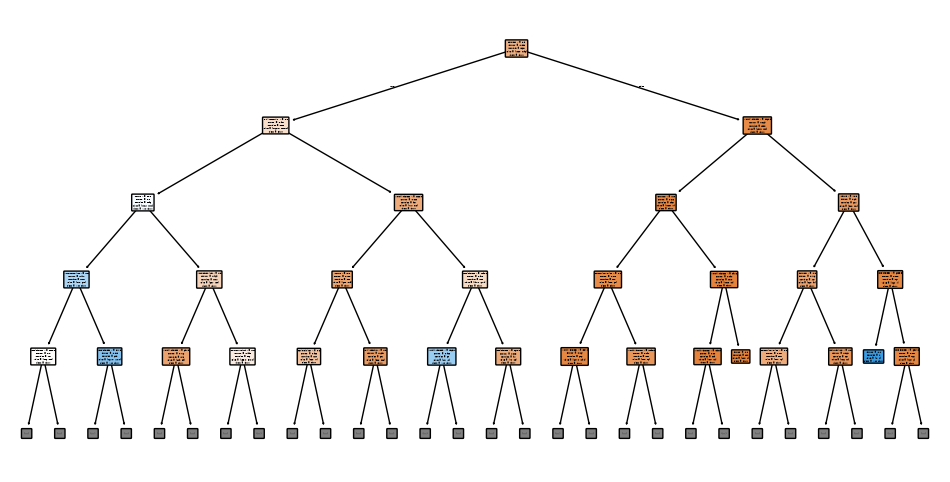

In [15]:
#plotting decision tree
import matplotlib.pyplot as plt
plt.figure(figsize = (12,6))
plot_tree(model,feature_names = X_new.columns,class_names = ['Churn','Not Churn'],max_depth = 4,rounded = True,filled =  True)
plt.show()

In [16]:
# K-FOLD training
from sklearn.model_selection import cross_val_score
cv_score = cross_val_score(model,X_new,y,cv = 5)
cv_score

array([0.74166075, 0.7338538 , 0.71114265, 0.71164773, 0.73366477])

In [17]:
np.mean(cv_score)

np.float64(0.7263939407381121)

In [18]:
#stratifiesKfold
from sklearn.model_selection import StratifiedKFold
k = 5
skf = StratifiedKFold(n_splits = k,shuffle= True,random_state = 42)  #n_splits = k , shuffle on 
cv_score_new = cross_val_score(model,X_new,y,cv = skf)
np.mean(cv_score_new)

np.float64(0.7266796446544939)

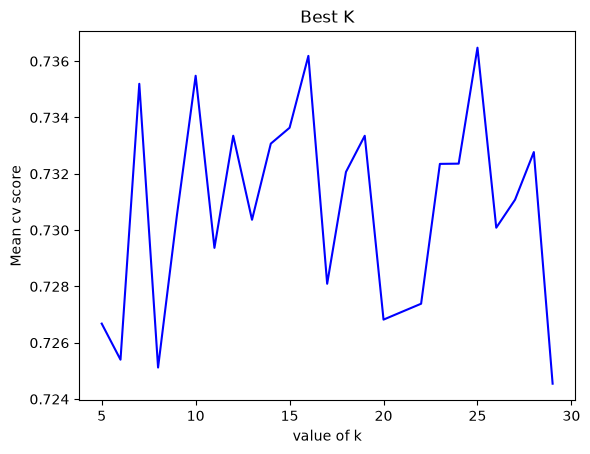

In [19]:
#checking for different values of k
cv_scores = []
for k in range(5,30):
    skf = StratifiedKFold(n_splits = k,shuffle= True,random_state = 42)  #n_splits = k , shuffle on 
    cv_score_new = cross_val_score(model,X_new,y,cv = skf)
    #now plot the figure
    cv_scores.append(np.mean(cv_score_new))
plt.plot(np.arange(5,30),cv_scores,color = 'b')
plt.xlabel("value of k")
plt.ylabel("Mean cv score")
plt.title("Best K")
plt.show()
    

In [20]:
#best value with low variance = 15
skf = StratifiedKFold(n_splits = 15,shuffle = True,random_state = 42)
cv_score_best = cross_val_score(model,X_new,y,cv = skf,scoring = 'accuracy')
np.mean(cv_score_best)

np.float64(0.733636074944427)

In [21]:
#here cv_score is by default using accuracy score 
#we can use cv_score = cross_val_score(model,X_new,y,scoring = 'recall') / precision also

In [23]:
#HYPERPARAMETER TUNING USING GRID SEARCH AND RANDOM SEARCH
from sklearn.model_selection import GridSearchCV,RandomizedSearchCV
dt_model = DecisionTreeClassifier(criterion = 'entropy',random_state = 42)


In [24]:
dt_model.fit(X_train,y_train)

,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.",'entropy'
,"random_state random_state: int, RandomState instance or None, default=NoneControls the randomness of the estimator. The features are alwaysrandomly permuted at each split, even if ``splitter`` is set to``""best""``. When ``max_features < n_features``, the algorithm willselect ``max_features`` at random at each split before finding the bestsplit among them. But the best found split may vary across differentruns, even if ``max_features=n_features``. That is the case, if theimprovement of the criterion is identical for several splits and onesplit has to be selected at random. To obtain a deterministic behaviourduring fitting, ``random_state`` has to be fixed to an integer.See :term:`Glossary <random_state>` for details.",42
,"splitter splitter: {""best"", ""random""}, default=""best""The strategy used to choose the split at each node. Supportedstrategies are ""best"" to choose the best split and ""random"" to choosethe best random split among considered features for this split.",'best'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: int, float or {""sqrt"", ""log2""}, default=NoneThe number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`.Note: splitting may inspect more than ``max_features`` features ifneeded to find a valid split.",None
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow a tree with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current node, ``N_t_L`` is the number of samp

In [33]:
parameter_grid = {'min_samples_split':[3,4,5,6,7],
'min_samples_leaf' :[1,3,6,9],
'max_depth': [4,5,6,7]
}

In [34]:
grid_search = GridSearchCV(estimator = dt_model,param_grid = parameter_grid,cv = 10,scoring = 'accuracy',
                           n_jobs = -1, #uses all cpu cores
                           verbose = 2 #to show the current progress 
                           )

In [36]:
#now fit in grid search
grid_search.fit(X_train,y_train)

Fitting 10 folds for each of 80 candidates, totalling 800 fits


,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",DecisionTreeC...ndom_state=42)
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'max_depth': [4, 5, ...], 'min_samples_leaf': [1, 3, ...], 'min_samples_split': [3, 4, ...]}"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",'accuracy'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-1
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",10
,"verbose verbose: int, default=0Controls the verbosity of information printed during fitting, with highervalues yielding more detailed logging.- 0 : no messages are printed;- >=1 : summary of the total number of fits;- >=2 : computation time for each fold and parameter candidate;- >=3 : fold indices and scores;- >=10 : parameter candidate indices and START messages before each fit.",2
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`sphx_glr_auto_examples_model_selection_plot

In [40]:
best_parameters = grid_search.best_params_
best_parameters

{'max_depth': 5, 'min_samples_leaf': 9, 'min_samples_split': 3}

In [37]:
new_best_model = grid_search.best_estimator_

In [38]:
pred = new_best_model.predict(X_test)
training_accuracy = accuracy_score(y_train,new_best_model.predict(X_train))
testing_accuracy =  accuracy_score(y_test,new_best_model.predict(X_test))

In [39]:
print(f"Training accuracy : {training_accuracy}")
print(f"testing accuracy : {testing_accuracy}")

Training accuracy : 0.7967696130635428
testing accuracy : 0.7977288857345636


In [43]:
from sklearn.metrics import classification_report
classify_report = classification_report(y_test,pred)
classify_report

'              precision    recall  f1-score   support\n\n           0       0.87      0.85      0.86      1036\n           1       0.61      0.64      0.63       373\n\n    accuracy                           0.80      1409\n   macro avg       0.74      0.75      0.74      1409\nweighted avg       0.80      0.80      0.80      1409\n'

In [45]:
#for randomized search import randint
from scipy.stats import randint
param =  {
    "min_samples_leaf": randint(3,15),
    "min_samples_split":randint(5,12),
    "max_depth" : randint(4,10)
}


In [48]:
#RANDOMIZED SEARCH
random_search = RandomizedSearchCV(estimator = dt_model,cv = 5, param_distributions = param,
                                  n_iter = 100, #no_of_iterations
                                  n_jobs = -1,verbose = 2)

In [49]:
#fit the model
random_search.fit(X_train,y_train)

Fitting 5 folds for each of 100 candidates, totalling 500 fits


,"estimator estimator: estimator objectAn object of that type is instantiated for each grid point.This is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",DecisionTreeC...ndom_state=42)
,"param_distributions param_distributions: dict or list of dictsDictionary with parameters names (`str`) as keys and distributionsor lists of parameters to try. Distributions must provide a ``rvs``method for sampling (such as those from scipy.stats.distributions).If a list is given, it is sampled uniformly.If a list of dicts is given, first a dict is sampled uniformly, andthen a parameter is sampled using that dict as above.","{'max_depth': <scipy.stats....002094D0F7ED0>, 'min_samples_leaf': <scipy.stats....002094DF0A7B0>, 'min_samples_split': <scipy.stats....002094D0F7610>}"
,"n_iter n_iter: int, default=10Number of parameter settings that are sampled. n_iter tradesoff runtime vs quality of the solution.",100
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-1
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",5
,"verbose verbose: int, default = 0Controls the verbosity of information printed during fitting, with highervalues yielding more detailed logging.- 0 : no messages are printed;- >=1 : summary of the total number of fits;- >=2 : computation time for each fold and parameter candidate;- >=3 : fold indices and scores;- >=10 : parameter candidate indices and START messages before each fit.",2
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.If None, the estimator's score method is used.",None
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given the ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribut

In [50]:
new_model = random_search.best_estimator_

In [51]:
pred = new_model.predict(X_test)
training_accuracy = accuracy_score(y_train,new_model.predict(X_train))
testing_accuracy =  accuracy_score(y_test,new_model.predict(X_test))


In [52]:
training_accuracy

0.7973020944266951

In [53]:
testing_accuracy

0.7977288857345636

In [54]:
classif_report = classification_report(y_test,pred)
classif_report

'              precision    recall  f1-score   support\n\n           0       0.87      0.85      0.86      1036\n           1       0.61      0.64      0.63       373\n\n    accuracy                           0.80      1409\n   macro avg       0.74      0.75      0.74      1409\nweighted avg       0.80      0.80      0.80      1409\n'